# Dungeon Master Automático con LangGraph: Agente con Estado, Herramientas y Memoria

**Proyecto Final — NLP (MMIA 6021 4889)**  
**Pablo Encalada**  
**Octubre 2026**

---

## 1. Problema

Los LLMs generan texto narrativo convincente, pero **no mantienen estado**. En una partida de rol (D&D), el Dungeon Master debe recordar en todo momento el inventario del jugador, sus puntos de vida, su ubicación, los NPCs que ha conocido y las decisiones que ha tomado. Un LLM vanilla:

- **Olvida el inventario**: el jugador recoge una espada en el turno 3 y el LLM no la menciona en el turno 8.
- **Contradice la narrativa**: dice que la puerta está cerrada después de que el jugador ya la abrió.
- **Alucina mecánicas**: inventa tiradas de dados con resultados arbitrarios, sin reglas consistentes.

### Diseño experimental

| | Línea base | Solución propuesta |
|---|---|---|
| **Método** | LLM directo (chat sin estado) | Agente LangGraph con estado + herramientas |
| **Técnica del curso** | Prompting básico (Sem. 1) | Agentes con herramientas y estado (Sem. 3-4, ReAct) |
| **Estado** | Solo en el contexto del chat | `game_state` externo en Python |

Ambos sistemas usan el **mismo modelo** (qwen2.5:7B) con el **mismo contexto**. La diferencia es que el agente tiene herramientas (`move_to`, `attack_enemy`, `check_state`, etc.) que interactúan con un estado de juego en Python que nunca se pierde ni se alucina.

La **métrica principal** es la **tasa de consistencia narrativa**: en una secuencia de 25 acciones preestablecidas, ¿cuántas veces el sistema responde de forma consistente con el estado real del juego? Se evalúa con dos métodos: keywords (determinista) y LLM-as-judge con logprobs (semántico, patrón de la Semana 2).

In [1]:
import time, random, re, json, textwrap
from typing import Annotated, TypedDict

import pandas as pd
import matplotlib.pyplot as plt

from langchain_ollama import ChatOllama
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_core.tools import tool

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode

print("Imports OK")

Imports OK


In [2]:
# ────────────────────────────────────────────────────────────────────────────
# Configuración del LLM
# ────────────────────────────────────────────────────────────────────────────

OLLAMA_MODEL = "qwen2.5:latest"  # 7B Q4_K_M
OLLAMA_BASE_URL = "http://localhost:11434"

llm = ChatOllama(
    model=OLLAMA_MODEL,
    base_url=OLLAMA_BASE_URL,
    temperature=0.7,
)

# Verificar conexión
try:
    resp = llm.invoke("Di solo OK")
    print(f"Ollama conectado. Modelo: {OLLAMA_MODEL}")
    print(f"Respuesta: {resp.content[:80]}")
except Exception as e:
    print(f"ERROR: No se pudo conectar a Ollama en {OLLAMA_BASE_URL}")
    print(f"  {e}")
    print(f"  ollama pull {OLLAMA_MODEL}")

Ollama conectado. Modelo: qwen2.5:latest
Respuesta: OK. 如果您需要更多信息或有其他问题，请告诉我。


## 2. Datos y definicion del mundo

No hay un dataset externo: el "dato" es la **definicion del mundo de juego** y las **reglas mecanicas** que el Dungeon Master debe seguir. Esto incluye:

- Un mapa con 5 ubicaciones conectadas
- NPCs con nombre, ubicacion y dialogo
- Objetos distribuidos por el mapa
- Reglas de combate simplificadas (basadas en el SRD de D&D 5e, que es Creative Commons)
- Estado inicial del jugador (HP, inventario, ubicacion)

In [3]:
# ────────────────────────────────────────────────────────────────────────────
# Definicion del mundo de juego
# ────────────────────────────────────────────────────────────────────────────

WORLD = {
    "locations": {
        "taberna": {
            "description": "Una taberna calida con olor a estofado. Un fuego crepita en la chimenea.",
            "connections": ["plaza", "bosque"],
            "items": ["antorcha"],
            "npcs": ["Goruk el tabernero"],
        },
        "plaza": {
            "description": "La plaza central del pueblo. Una fuente de piedra en el centro. Hay un tablero de anuncios.",
            "connections": ["taberna", "herreria", "bosque"],
            "items": [],
            "npcs": ["Elena la comerciante"],
        },
        "herreria": {
            "description": "El calor del horno es sofocante. Espadas y escudos cuelgan de las paredes.",
            "connections": ["plaza"],
            "items": ["escudo de hierro"],
            "npcs": ["Bron el herrero"],
        },
        "bosque": {
            "description": "Arboles altos bloquean la luz. Se escuchan ruidos entre la maleza.",
            "connections": ["plaza", "taberna", "cueva"],
            "items": ["hierbas medicinales"],
            "npcs": [],
        },
        "cueva": {
            "description": "Una cueva oscura y humeda. Huesos viejos esparcidos por el suelo. El aire huele a azufre.",
            "connections": ["bosque"],
            "items": ["cofre con 50 monedas de oro"],
            "npcs": ["Goblin centinela"],
        },
    },
    "npcs": {
        "Goruk el tabernero": {
            "dialogue": "Bienvenido, viajero. Ten cuidado en el bosque, dicen que hay goblins en la cueva del norte.",
            "hostile": False,
        },
        "Elena la comerciante": {
            "dialogue": "Vendo pociones de curacion por 10 monedas de oro. Tambien compro hierbas medicinales.",
            "hostile": False,
        },
        "Bron el herrero": {
            "dialogue": "Puedo afilar tu espada por 5 monedas de oro. El goblin de la cueva le tiene miedo al fuego.",
            "hostile": False,
        },
        "Goblin centinela": {
            "dialogue": "¡Intruso! ¡Este es MI tesoro!",
            "hostile": True,
            "hp": 12,
            "attack": "1d6",
            "defense": 10,
        },
    },
}

# Estado inicial del jugador
INITIAL_STATE = {
    "player_name": "Aventurero",
    "hp": 20,
    "max_hp": 20,
    "gold": 15,
    "inventory": ["espada oxidada", "pocion de curacion"],
    "location": "taberna",
    "events": [],  # registro de eventos clave
}

print("Mundo de juego:")
for loc, data in WORLD["locations"].items():
    conns = ", ".join(data["connections"])
    print(f"  {loc:<12} -> conecta con: {conns}")
print(f"\nJugador inicia en: {INITIAL_STATE['location']}")
print(f"HP: {INITIAL_STATE['hp']}/{INITIAL_STATE['max_hp']}")
print(f"Oro: {INITIAL_STATE['gold']}")
print(f"Inventario: {INITIAL_STATE['inventory']}")

Mundo de juego:
  taberna      -> conecta con: plaza, bosque
  plaza        -> conecta con: taberna, herreria, bosque
  herreria     -> conecta con: plaza
  bosque       -> conecta con: plaza, taberna, cueva
  cueva        -> conecta con: bosque

Jugador inicia en: taberna
HP: 20/20
Oro: 15
Inventario: ['espada oxidada', 'pocion de curacion']


## 3. Linea base: LLM directo (sin estado ni herramientas)

El enfoque mas simple: se le da al LLM un system prompt con las reglas del mundo y se le pide que actue como Dungeon Master. Todo el historial de la partida se pasa como mensajes de chat. El LLM no tiene herramientas, no tiene estado externo — debe "recordar" todo del contexto de la conversacion.

**Limitaciones esperadas:**
- El LLM inventa resultados de dados en vez de tirarlos
- A medida que crece la conversacion, pierde de vista el inventario y los HP
- No puede validar movimientos (puede dejar al jugador "teletransportarse")

In [4]:
# ────────────────────────────────────────────────────────────────────────────
# Linea base: LLM directo como Dungeon Master
# ────────────────────────────────────────────────────────────────────────────

SYSTEM_PROMPT_BASELINE = """\
Eres un Dungeon Master de D&D. Narras una aventura interactiva en espanol.

MUNDO:
- Ubicaciones: taberna, plaza, herreria, bosque, cueva.
- Taberna conecta con plaza y bosque. Plaza conecta con taberna, herreria y bosque. \
Herreria conecta con plaza. Bosque conecta con plaza, taberna y cueva. Cueva conecta con bosque.
- En la taberna esta Goruk el tabernero y hay una antorcha.
- En la plaza esta Elena la comerciante.
- En la herreria esta Bron el herrero y hay un escudo de hierro.
- En el bosque hay hierbas medicinales.
- En la cueva hay un Goblin centinela (hostil, 12 HP) y un cofre con 50 monedas de oro.

JUGADOR INICIAL:
- HP: 20/20, Oro: 15, Inventario: espada oxidada, pocion de curacion
- Ubicacion: taberna

REGLAS:
- El jugador solo puede moverse a ubicaciones conectadas.
- En combate, el jugador y el enemigo tiran 1d20 para atacar. Si sacan >= 10, aciertan. \
El dano es 1d6 para el jugador y 1d6 para el goblin.
- La pocion de curacion restaura 2d4+2 HP.
- Narra de forma breve (3-4 oraciones por turno). Al final de cada turno, muestra \
el estado: [HP: X/20 | Oro: X | Ubicacion: X | Inventario: ...]"""


class BaselineDM:
    """Dungeon Master sin estado externo: solo chat directo."""

    def __init__(self, llm):
        self.llm = llm
        self.messages = [SystemMessage(content=SYSTEM_PROMPT_BASELINE)]
        self.turn_times = []

    def play(self, action: str) -> str:
        self.messages.append(HumanMessage(content=action))
        t0 = time.time()
        response = self.llm.invoke(self.messages)
        self.turn_times.append(time.time() - t0)
        self.messages.append(response)
        return response.content


# Prueba rapida
baseline_dm = BaselineDM(llm)
resp = baseline_dm.play("Miro a mi alrededor en la taberna.")
print("BASELINE — Turno 1:")
print(textwrap.fill(resp, width=80))
print(f"\n(Tiempo: {baseline_dm.turn_times[-1]:.2f}s)")

BASELINE — Turno 1:
La taberna está iluminada con la tenue luz de una antorcha en el centro. Goruk,
el tabernero, te observa con curiosidad mientras lavas vasos en el mostrador.
Afuera, la plaza se ve concurrida, y el ruido de la herrería se escucha
levemente. El bosque, con sus árboles oscuros, se adivina a través de las
ventanas.  [HP: 20/20 | Oro: 15 | Ubicacion: taberna | Inventario: espada
oxidada, pocion de curacion]

(Tiempo: 7.53s)


## 4. Solucion propuesta: Agente LangGraph con estado y herramientas

El agente tiene tres componentes que el baseline no tiene:

1. **Estado explicito** (`TypedDict`): HP, inventario, oro, ubicacion y registro de eventos se mantienen fuera del LLM, como variables de Python. El LLM no puede "olvidarlos".

2. **Herramientas** que el LLM puede invocar via tool-calling (patron ReAct):
   - `roll_dice`: tira dados reales (`2d6+3` → resultado aleatorio reproducible)
   - `check_state`: consulta HP, inventario, ubicacion, oro actuales
   - `move_to`: valida y ejecuta movimiento (solo a ubicaciones conectadas)
   - `pick_up_item`: recoge un objeto si existe en la ubicacion actual
   - `use_potion`: consume una pocion y actualiza HP
   - `attack_enemy`: resuelve un turno de combate con tiradas reales

3. **Grafo LangGraph**: orquesta el ciclo agente → herramientas → agente, con el estado del juego como contexto inyectado en cada turno.

In [5]:
# ────────────────────────────────────────────────────────────────────────────
# 4.1 Estado del juego y herramientas
# ────────────────────────────────────────────────────────────────────────────

# Estado mutable del juego (vive fuera del LLM)
game_state = {}


def reset_game_state():
    """Reinicia el estado del juego a los valores iniciales."""
    global game_state
    game_state = {
        "hp": INITIAL_STATE["hp"],
        "max_hp": INITIAL_STATE["max_hp"],
        "gold": INITIAL_STATE["gold"],
        "inventory": list(INITIAL_STATE["inventory"]),
        "location": INITIAL_STATE["location"],
        "events": [],
        "items_taken": [],      # objetos ya recogidos (no reaparecen)
        "enemies_defeated": [],  # enemigos ya derrotados
    }


def _roll(notation: str) -> int:
    """Parsea notacion de dados (ej: '2d6+3') y devuelve el resultado."""
    notation = notation.strip().lower()
    m = re.match(r"(\d+)d(\d+)([+-]\d+)?", notation)
    if not m:
        return random.randint(1, 20)
    n, sides, mod = int(m.group(1)), int(m.group(2)), int(m.group(3) or 0)
    return sum(random.randint(1, sides) for _ in range(n)) + mod


def _state_summary() -> str:
    """Resumen del estado actual para inyectar en el prompt."""
    inv = ", ".join(game_state["inventory"]) if game_state["inventory"] else "(vacio)"
    return (
        f"[HP: {game_state['hp']}/{game_state['max_hp']} | "
        f"Oro: {game_state['gold']} | "
        f"Ubicacion: {game_state['location']} | "
        f"Inventario: {inv}]"
    )


# --- Herramientas (decoradas con @tool para LangChain) ---

@tool
def roll_dice(notation: str) -> str:
    """Tira dados con notacion estandar (ej: '1d20', '2d6+3'). Devuelve el resultado."""
    result = _roll(notation)
    return f"Tiraste {notation}: resultado = {result}"


@tool
def check_state() -> str:
    """Consulta el estado actual del jugador: HP, oro, inventario y ubicacion."""
    loc = game_state["location"]
    loc_data = WORLD["locations"][loc]
    available_items = [i for i in loc_data["items"] if i not in game_state["items_taken"]]
    npcs_here = [n for n in loc_data["npcs"] if n not in game_state["enemies_defeated"]]
    connections = ", ".join(loc_data["connections"])

    return (
        f"Estado del jugador: {_state_summary()}\n"
        f"Descripcion del lugar: {loc_data['description']}\n"
        f"Objetos aqui: {available_items or 'ninguno'}\n"
        f"NPCs aqui: {npcs_here or 'nadie'}\n"
        f"Puedes ir a: {connections}\n"
        f"Eventos previos: {game_state['events'][-5:] if game_state['events'] else 'ninguno'}"
    )


@tool
def move_to(destination: str) -> str:
    """Mueve al jugador a una ubicacion conectada. Valida que el movimiento sea legal."""
    dest = destination.strip().lower()
    current = game_state["location"]
    connections = WORLD["locations"][current]["connections"]

    if dest not in connections:
        return f"No puedes ir a '{dest}' desde {current}. Destinos validos: {', '.join(connections)}"

    game_state["location"] = dest
    game_state["events"].append(f"Se movio de {current} a {dest}")
    loc_data = WORLD["locations"][dest]
    npcs = [n for n in loc_data["npcs"] if n not in game_state["enemies_defeated"]]
    items = [i for i in loc_data["items"] if i not in game_state["items_taken"]]

    return (
        f"Te mueves a: {dest}. {loc_data['description']}\n"
        f"NPCs aqui: {npcs or 'nadie'}. Objetos: {items or 'ninguno'}.\n"
        f"{_state_summary()}"
    )


@tool
def pick_up_item(item_name: str) -> str:
    """Recoge un objeto de la ubicacion actual y lo anade al inventario."""
    item = item_name.strip().lower()
    loc = game_state["location"]
    available = [i for i in WORLD["locations"][loc]["items"] if i not in game_state["items_taken"]]
    available_lower = [i.lower() for i in available]

    if item not in available_lower:
        return f"No hay '{item}' aqui. Objetos disponibles: {available or 'ninguno'}"

    idx = available_lower.index(item)
    real_name = available[idx]
    game_state["inventory"].append(real_name)
    game_state["items_taken"].append(real_name)
    game_state["events"].append(f"Recogio: {real_name}")
    return f"Recogiste: {real_name}. {_state_summary()}"


@tool
def use_potion() -> str:
    """Usa una pocion de curacion del inventario. Restaura 2d4+2 HP."""
    if "pocion de curacion" not in game_state["inventory"]:
        return f"No tienes pociones de curacion. Inventario: {game_state['inventory']}"

    heal = _roll("2d4+2")
    game_state["inventory"].remove("pocion de curacion")
    old_hp = game_state["hp"]
    game_state["hp"] = min(game_state["hp"] + heal, game_state["max_hp"])
    game_state["events"].append(f"Uso pocion: +{heal} HP ({old_hp} -> {game_state['hp']})")
    return f"Bebiste la pocion. Recuperas {heal} HP. {_state_summary()}"


@tool
def attack_enemy(enemy_name: str) -> str:
    """Resuelve un turno de combate contra un enemigo en la ubicacion actual."""
    loc = game_state["location"]
    npcs_here = [n for n in WORLD["locations"][loc].get("npcs", [])
                 if n not in game_state["enemies_defeated"]]

    # Buscar el enemigo
    enemy = None
    for npc in npcs_here:
        if enemy_name.lower() in npc.lower():
            enemy = npc
            break
    if not enemy:
        return f"No hay enemigo '{enemy_name}' aqui. NPCs presentes: {npcs_here or 'nadie'}"

    npc_data = WORLD["npcs"][enemy]
    if not npc_data.get("hostile", False):
        return f"{enemy} no es hostil. Puedes hablar con el/ella."

    # Tirada del jugador
    player_roll = _roll("1d20")
    player_hits = player_roll >= 10
    player_dmg = _roll("1d6") if player_hits else 0

    # Tirada del enemigo
    enemy_roll = _roll("1d20")
    enemy_hits = enemy_roll >= 10
    enemy_dmg = _roll(npc_data.get("attack", "1d6")) if enemy_hits else 0

    # Aplicar dano (simplificado: usamos HP del estado para el enemigo tambien)
    result = f"--- COMBATE vs {enemy} ---\n"
    result += f"Tu ataque: d20={player_roll} -> {'ACIERTO' if player_hits else 'FALLO'}"
    if player_hits:
        result += f", {player_dmg} de dano"
    result += f"\nAtaque de {enemy}: d20={enemy_roll} -> {'ACIERTO' if enemy_hits else 'FALLO'}"
    if enemy_hits:
        game_state["hp"] = max(0, game_state["hp"] - enemy_dmg)
        result += f", {enemy_dmg} de dano a ti"

    # Simplificacion: el goblin muere si el jugador acierta (para no complicar HP del NPC)
    if player_hits:
        game_state["enemies_defeated"].append(enemy)
        game_state["events"].append(f"Derroto a {enemy} (tiro {player_roll}, dano {player_dmg})")
        result += f"\n¡{enemy} ha sido derrotado!"
    else:
        game_state["events"].append(f"Combate con {enemy}: fallo (tiro {player_roll})")
        result += f"\n{enemy} sigue en pie."

    result += f"\n{_state_summary()}"
    return result


TOOLS = [roll_dice, check_state, move_to, pick_up_item, use_potion, attack_enemy]
print(f"Herramientas registradas: {[t.name for t in TOOLS]}")

Herramientas registradas: ['roll_dice', 'check_state', 'move_to', 'pick_up_item', 'use_potion', 'attack_enemy']


In [6]:
# ────────────────────────────────────────────────────────────────────────────
# 4.2 Grafo LangGraph: ciclo agente <-> herramientas
# ────────────────────────────────────────────────────────────────────────────

# Estado del grafo (mensajes de chat)
class AgentState(TypedDict):
    messages: Annotated[list, add_messages]


# System prompt del agente: muy directivo sobre cuándo usar cada herramienta
SYSTEM_PROMPT_AGENT = """\
Eres un Dungeon Master de D&D. Narras una aventura interactiva en español.

INSTRUCCIONES OBLIGATORIAS — debes seguir estas reglas en CADA turno:

1. SIEMPRE llama a check_state PRIMERO para conocer el estado actual del jugador.
2. Si el jugador quiere MOVERSE, usa move_to (NUNCA describas un movimiento sin llamar a move_to).
3. Si el jugador quiere RECOGER algo, usa pick_up_item.
4. Si el jugador quiere ATACAR, usa attack_enemy.
5. Si el jugador quiere CURARSE, usa use_potion.
6. Para CUALQUIER tirada de dados, usa roll_dice (NUNCA inventes un número).
7. Después de usar herramientas, narra brevemente (2-3 oraciones) y muestra el estado del jugador.

NUNCA respondas sin usar al menos check_state primero. NUNCA describas una acción mecánica sin usar la herramienta correspondiente."""

# LLM con herramientas vinculadas
llm_with_tools = llm.bind_tools(TOOLS)


def agent_node(state: AgentState):
    """Nodo agente: decide si usar herramientas o responder."""
    # Inyectar estado del juego en el system prompt para que el LLM lo tenga presente
    state_info = _state_summary()
    system = SYSTEM_PROMPT_AGENT + f"\n\nESTADO ACTUAL DEL JUEGO: {state_info}"
    messages = [SystemMessage(content=system)] + state["messages"]
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}


def should_continue(state: AgentState):
    """Decide si el agente necesita ejecutar herramientas o ya terminó."""
    last = state["messages"][-1]
    if hasattr(last, "tool_calls") and last.tool_calls:
        return "tools"
    return END


# Construir el grafo
tool_node = ToolNode(TOOLS)

graph = StateGraph(AgentState)
graph.add_node("agent", agent_node)
graph.add_node("tools", tool_node)
graph.add_edge(START, "agent")
graph.add_conditional_edges("agent", should_continue, {"tools": "tools", END: END})
graph.add_edge("tools", "agent")

app = graph.compile()
print("Grafo LangGraph compilado:")
print("  START -> agent -> (tools -> agent)* -> END")

Grafo LangGraph compilado:
  START -> agent -> (tools -> agent)* -> END


In [7]:
# ────────────────────────────────────────────────────────────────────────────
# 4.3 Clase wrapper para el agente DM
# ────────────────────────────────────────────────────────────────────────────

class AgentDM:
    """Dungeon Master con estado y herramientas (LangGraph)."""

    def __init__(self, app):
        self.app = app
        self.state = {"messages": []}
        self.turn_times = []
        reset_game_state()

    def play(self, action: str) -> str:
        self.state["messages"].append(HumanMessage(content=action))
        t0 = time.time()
        result = self.app.invoke(self.state)
        self.turn_times.append(time.time() - t0)
        self.state = result

        # Extraer la ultima respuesta del agente (no las tool calls)
        for msg in reversed(result["messages"]):
            if isinstance(msg, AIMessage) and msg.content and not msg.tool_calls:
                return msg.content
        # Fallback: devolver el ultimo mensaje
        return result["messages"][-1].content if result["messages"] else "(sin respuesta)"


# Prueba rapida
agent_dm = AgentDM(app)
resp = agent_dm.play("Miro a mi alrededor en la taberna.")
print("AGENTE — Turno 1:")
print(textwrap.fill(resp, width=80))
print(f"\n(Tiempo: {agent_dm.turn_times[-1]:.2f}s)")
print(f"Estado real: {_state_summary()}")

AGENTE — Turno 1:
Bienvenido de nuevo, aventurero. La taberna está tranquila hoy. Puedes ver a los
lugareños charlando y bebiendo en las mesas. Al fondo, el dueño está limpiando
la barra. ¿Qué te traería el día? ¿Te gustaría explorar un poco más o pedir una
bebida?

(Tiempo: 6.14s)
Estado real: [HP: 20/20 | Oro: 15 | Ubicacion: taberna | Inventario: espada oxidada, pocion de curacion]


## 5. Evaluación: secuencia de prueba automatizada

Para comparar ambos enfoques de forma cuantitativa, ejecutamos la **misma secuencia de 15 acciones** en ambos sistemas y medimos:

1. **Consistencia de inventario**: ¿menciona los objetos que recogió?
2. **Consistencia de ubicación**: ¿sabe dónde está?
3. **Consistencia de HP**: ¿reporta los HP correctos?
4. **Validación de movimiento**: ¿permite movimientos ilegales?
5. **Dados reales vs inventados**: ¿usa dados aleatorios o los inventa?

Después de cada acción, hacemos una **pregunta de verificación** ("¿qué tengo en el inventario?", "¿dónde estoy?") y comparamos la respuesta contra el estado real.

### Dos métodos de evaluación

| Método | Cómo funciona | Ventaja | Debilidad |
|--------|---------------|---------|-----------|
| **Keywords** | Busca palabras clave en la respuesta | Rápido, determinista | Frágil con sinónimos |
| **LLM-as-judge** | Un segundo LLM evalúa si la respuesta es consistente | Entiende paráfrasis y sinónimos | Más lento, no determinista |

Usar ambos métodos nos da una evaluación más robusta y nos permite comparar qué tan de acuerdo están entre sí.

In [8]:
# ────────────────────────────────────────────────────────────────────────────
# Secuencia de prueba: 25 turnos con memoria a largo plazo
# ────────────────────────────────────────────────────────────────────────────
#
# Diseñada para ESTIRAR el contexto: a medida que crece la conversación,
# el baseline pierde información vieja mientras el agente consulta game_state.
# Los turnos 16-25 preguntan por cosas que ocurrieron 10-20 turnos atrás.

TEST_SEQUENCE = [
    # === BLOQUE 1: exploración y recolección (turnos 1-5) ===

    ("Miro a mi alrededor en la taberna.",
     "¿Qué objetos hay aquí que pueda recoger?",
     "item_mention", "antorcha"),

    ("Recojo la antorcha.",
     "¿Qué tengo en mi inventario ahora?",
     "inventory", "antorcha"),

    ("Hablo con Goruk el tabernero.",
     "¿Dónde estoy?",
     "location", "taberna"),

    ("Voy al bosque.",
     "¿Dónde estoy ahora?",
     "location", "bosque"),

    ("Recojo las hierbas medicinales.",
     "¿Qué tengo en mi inventario?",
     "inventory", "hierbas"),

    # === BLOQUE 2: validación de reglas (turnos 6-7) ===

    ("Voy a la herrería.",
     "¿Pude ir a la herrería desde el bosque?",
     "illegal_move", "no"),

    ("¿Dónde estoy exactamente?",
     "¿Sigo en el bosque?",
     "location", "bosque"),

    # === BLOQUE 3: combate (turnos 8-11) ===

    ("Voy a la cueva.",
     "¿Dónde estoy?",
     "location", "cueva"),

    ("Reviso mi equipo antes de avanzar.",
     "¿Qué objetos tengo exactamente?",
     "inventory_full", "antorcha,hierbas medicinales,espada oxidada,pocion de curacion"),

    ("Ataco al goblin con mi espada.",
     "¿Cuántos HP tengo ahora?",
     "hp_mentioned", "hp"),

    ("Abro el cofre y tomo las monedas de oro.",
     "¿Cuánto oro tengo ahora?",
     "gold_change", "gold"),

    # === BLOQUE 4: navegación extendida (turnos 12-15) ===

    ("Vuelvo al bosque.",
     "¿Dónde estoy?",
     "location", "bosque"),

    ("Voy a la plaza.",
     "¿Dónde estoy ahora?",
     "location", "plaza"),

    ("Hablo con Elena la comerciante.",
     "¿Dónde estoy?",
     "location", "plaza"),

    ("Voy a la herrería.",
     "¿Dónde estoy ahora?",
     "location", "herreria"),

    # === BLOQUE 5: memoria a largo plazo — aquí se separa el trigo de la paja ===
    # El contexto ya tiene ~20 mensajes. El baseline empieza a perder detalles.

    # Turno 16: ¿Recuerdas el inventario completo? (acumulado en turnos 1-11)
    ("Reviso todo lo que llevo encima.",
     "¿Tengo la antorcha que recogí en la taberna al inicio?",
     "inventory", "antorcha"),

    # Turno 17: ¿Recuerdas el combate? (ocurrió en turno 10)
    ("Recuerdo la pelea en la cueva. ¿Qué pasó?",
     "¿Derroté al goblin o sigue vivo?",
     "event_memory", "derrot"),

    # Turno 18: volver a la taberna — ¿hay antorcha todavía?
    ("Voy a la plaza.",
     "¿Dónde estoy?",
     "location", "plaza"),

    ("Voy a la taberna.",
     "¿Dónde estoy ahora?",
     "location", "taberna"),

    # Turno 20: ¿La antorcha ya fue recogida? No debería estar aquí
    ("¿Hay algo que pueda recoger aquí en la taberna?",
     "¿Sigue la antorcha aquí o ya la recogí antes?",
     "item_gone", "antorcha"),

    # Turno 21: usar la poción
    ("Uso mi poción de curación.",
     "¿Se eliminó la poción de mi inventario?",
     "potion_used", "pocion"),

    # Turno 22: verificar HP tras poción
    ("¿Cuánta vida tengo?",
     "¿Cuántos HP tengo exactamente?",
     "hp_mentioned", "hp"),

    # Turno 23: segundo intento de movimiento ilegal (taberna → herrería)
    ("Voy a la herrería.",
     "¿Puedo ir directo de la taberna a la herrería?",
     "illegal_move", "no"),

    # Turno 24: verificar ubicación tras segundo ilegal
    ("¿Dónde estoy?",
     "¿Sigo en la taberna?",
     "location", "taberna"),

    # Turno 25: pregunta FINAL de memoria — inventario completo tras todos los cambios
    ("Antes de terminar, reviso mi inventario una última vez.",
     "¿Qué objetos tengo? ¿Tengo la poción todavía o ya la usé?",
     "potion_gone", "no tiene"),
]

print(f"Secuencia de prueba: {len(TEST_SEQUENCE)} pares (acción + verificación)")
print(f"Total de interacciones: {len(TEST_SEQUENCE) * 2} mensajes por sistema")
print(f"\nDesglose por tipo de verificación:")
from collections import Counter
counts = Counter(field for _, _, field, _ in TEST_SEQUENCE)
for field, n_field in counts.most_common():
    print(f"  {field:<18} {n_field} turnos")

Secuencia de prueba: 25 pares (acción + verificación)
Total de interacciones: 50 mensajes por sistema

Desglose por tipo de verificación:
  location           11 turnos
  inventory          3 turnos
  illegal_move       2 turnos
  hp_mentioned       2 turnos
  item_mention       1 turnos
  inventory_full     1 turnos
  gold_change        1 turnos
  event_memory       1 turnos
  item_gone          1 turnos
  potion_used        1 turnos
  potion_gone        1 turnos


In [9]:
# ────────────────────────────────────────────────────────────────────────────
# 5.1 Ejecutar el BASELINE sobre la secuencia completa
# ────────────────────────────────────────────────────────────────────────────

print("=" * 78)
print("EJECUTANDO BASELINE (LLM directo, sin estado)")
print("=" * 78)

baseline_dm = BaselineDM(llm)
baseline_responses = []

for i, (action, question, field, expected) in enumerate(TEST_SEQUENCE):
    print(f"\n--- Turno {i+1} ---")
    # Accion
    resp_action = baseline_dm.play(action)
    print(f"Jugador: {action}")
    print(f"DM: {resp_action[:200]}...")

    # Pregunta de verificacion
    resp_check = baseline_dm.play(question)
    print(f"Verificacion: {question}")
    print(f"DM: {resp_check[:200]}...")

    baseline_responses.append({
        "turn": i + 1,
        "action": action,
        "question": question,
        "response_action": resp_action,
        "response_check": resp_check,
        "field": field,
        "expected": expected,
    })

print(f"\nBaseline completado. Turnos: {len(baseline_responses)}")
print(f"Tiempo total: {sum(baseline_dm.turn_times):.1f}s")

EJECUTANDO BASELINE (LLM directo, sin estado)

--- Turno 1 ---


Jugador: Miro a mi alrededor en la taberna.
DM: En la taberna, el ambiente es bullicioso. Goruk el tabernero te mira con curiosidad mientras prepara una nueva taza de cerveza. La antorcha en el centro de la taberna brilla tenue, iluminando a los po...


Verificacion: ¿Qué objetos hay aquí que pueda recoger?
DM: En la taberna, puedes ver la antorcha en el centro y posiblemente recogerla. También puedes hablar con Goruk el tabernero. ¿Qué te gustaría hacer?...

--- Turno 2 ---


Jugador: Recojo la antorcha.
DM: Bien, has recogido la antorcha. Ahora iluminas mejor la taberna y te sientes un poco más preparado para cualquier aventura que se te presente. [HP: 20/20 | Oro: 15 | Ubicacion: taberna | Inventario: e...


Verificacion: ¿Qué tengo en mi inventario ahora?
DM: Actualmente, tu inventario incluye:
- Espada oxidada
- Poción de curación
- Antorcha

¿Qué te gustaría hacer ahora? ¿Te gustaría hablar con Goruk el tabernero, ir a la plaza, a la herrería o a alguna ...

--- Turno 3 ---


Jugador: Hablo con Goruk el tabernero.
DM: Goruk el tabernero te mira amablemente y te invita a sentarte a una de las taburetes. "Bienvenido, aventurero. ¿Qué trae a la taberna hoy? ¿Buscas información, una bebida fuerte, o tal vez algo más?" ...


... (41 outputs left out)

Jugador: ¿Dónde estoy?
DM: Estás en la herrería. Goruk te saluda amablemente cuando pasas por la taberna, y ahora estás en el ambiente de la herrería, donde puedes ver a Bron el herrero trabajando en un nuevo objeto, golpeando ...


Verificacion: ¿Sigo en la taberna?
DM: Siento la confusión. Ya has salido de la taberna y te has dirigido a la herrería. Ahora estás en la herrería.

[HP: 20/20 | Oro: 65 | Ubicación: herrería | Inventario: espada oxidada, antorcha, hierba...

--- Turno 25 ---


Jugador: Antes de terminar, reviso mi inventario una última vez.
DM: Revisas tu inventario una última vez para asegurarte de que nada se te haya pasado desapercibido.

[HP: 20/20 | Oro: 65 | Ubicación: herrería | Inventario: espada oxidada, antorcha, hierbas medicinale...


Verificacion: ¿Qué objetos tengo? ¿Tengo la poción todavía o ya la usé?
DM: Vuelves a revisar tu inventario con atención. Observas que tienes los siguientes objetos:

- Espada oxidada
- Antorcha
- Hierbas medicinales
- 50 monedas de oro

La poción de curación ya no está en tu...

Baseline completado. Turnos: 25
Tiempo total: 819.7s


In [10]:
# ────────────────────────────────────────────────────────────────────────────
# 5.2 Ejecutar el AGENTE sobre la secuencia completa
# ────────────────────────────────────────────────────────────────────────────

print("=" * 78)
print("EJECUTANDO AGENTE (LangGraph con estado + herramientas)")
print("=" * 78)

agent_dm = AgentDM(app)
agent_responses = []

for i, (action, question, field, expected) in enumerate(TEST_SEQUENCE):
    print(f"\n--- Turno {i+1} ---")
    # Accion
    resp_action = agent_dm.play(action)
    print(f"Jugador: {action}")
    print(f"DM: {resp_action[:200]}...")

    # Pregunta de verificacion
    resp_check = agent_dm.play(question)
    print(f"Verificacion: {question}")
    print(f"DM: {resp_check[:200]}...")

    # Registrar el estado REAL del juego en este punto
    agent_responses.append({
        "turn": i + 1,
        "action": action,
        "question": question,
        "response_action": resp_action,
        "response_check": resp_check,
        "field": field,
        "expected": expected,
        "real_state": dict(game_state),  # snapshot del estado real
    })

print(f"\nAgente completado. Turnos: {len(agent_responses)}")
print(f"Tiempo total: {sum(agent_dm.turn_times):.1f}s")
print(f"Estado final real: {_state_summary()}")

EJECUTANDO AGENTE (LangGraph con estado + herramientas)

--- Turno 1 ---


Jugador: Miro a mi alrededor en la taberna.
DM: La taberna está animada, con clientes bebiendo y charlando. En el suelo, ves un pequeño objeto brillante. Algunos clientes beben cerveza a lo lejos y un tablero de ajedrez descansa en una mesa....


Verificacion: ¿Qué objetos hay aquí que pueda recoger?
DM: En el suelo, puedes ver un pequeño objeto brillante. También hay una moneda cerca de la barra. ¿Qué te gustaría recoger?...

--- Turno 2 ---


Jugador: Recojo la antorcha.
DM: Has recogido la antorcha. Ahora tienes más luz con que iluminar la taberna. [HP: 20/20 | Oro: 15 | Ubicacion: taberna | Inventario: espada oxidada, pocion de curacion, antorcha]...


Verificacion: ¿Qué tengo en mi inventario ahora?
DM: Actualmente tienes el siguiente inventario: [HP: 20/20 | Oro: 15 | Ubicacion: taberna | Inventario: espada oxidada, pocion de curacion, antorcha]...

--- Turno 3 ---


Jugador: Hablo con Goruk el tabernero.
DM: Goruk el tabernero te mira y te invita a sentarte. "¿En qué puedo ayudarte hoy, aventurero?" te pregunta. Parece dispuesto a escucharte, pero también está atento a los demás clientes. ¿Qué te gustaría...


... (41 outputs left out)

Jugador: ¿Dónde estoy?
DM: Estás en la taberna. El lugar está cálido y perfumado con el aroma del estofado. Un fuego crepita en la chimenea. El tabernero Goruk te mira con curiosidad. [HP: 20/20 | Oro: 15 | Ubicación: taberna |...


Verificacion: ¿Sigo en la taberna?
DM: Sí, sigues en la taberna. El lugar está cálido y perfumado con el aroma del estofado. Un fuego crepita en la chimenea. El tabernero Goruk te mira con curiosidad. [HP: 20/20 | Oro: 15 | Ubicación: tabe...

--- Turno 25 ---


Jugador: Antes de terminar, reviso mi inventario una última vez.
DM: Actualmente tienes el siguiente inventario: [HP: 20/20 | Oro: 15 | Ubicación: taberna | Inventario: espada oxidada, antorcha, hierbas medicinales, cofre con 50 monedas de oro]

¿Quieres hacer algo en ...


Verificacion: ¿Qué objetos tengo? ¿Tengo la poción todavía o ya la usé?
DM: Actualmente tienes los siguientes objetos en tu inventario: espada oxidada, antorcha, hierbas medicinales y cofre con 50 monedas de oro. Ya has usado la poción de curación.

¿Quieres hablar con el tab...

Agente completado. Turnos: 25
Tiempo total: 915.5s
Estado final real: [HP: 20/20 | Oro: 15 | Ubicacion: taberna | Inventario: espada oxidada, antorcha, hierbas medicinales, cofre con 50 monedas de oro]


In [11]:
# ────────────────────────────────────────────────────────────────────────────
# 5.3 Evaluación de consistencia: método 1 — Keywords
# ────────────────────────────────────────────────────────────────────────────

def check_consistency(response: str, field: str, expected: str) -> bool:
    """Verifica si la respuesta del DM es consistente con el estado esperado (keywords)."""
    resp = response.lower()

    if field == "item_mention":
        return expected.lower() in resp

    elif field == "inventory":
        return expected.lower() in resp

    elif field == "location":
        return expected.lower() in resp

    elif field == "illegal_move":
        illegal_indicators = ["no puedes", "no puede", "no es posible", "no hay camino",
                              "imposible", "no conecta", "no lleva", "solo puedes ir",
                              "debes ir", "no tiene conexion", "no esta conectad",
                              "no hay ruta", "no directa"]
        went_there = "herreria" in resp and any(w in resp for w in
                     ["llegas", "entras", "estas en la herreria", "la herreria te"])
        if went_there:
            return False
        return any(ind in resp for ind in illegal_indicators) or "bosque" in resp or "taberna" in resp

    elif field == "inventory_full":
        items = expected.split(",")
        return sum(1 for item in items if item.strip().lower() in resp) >= 2

    elif field == "hp_mentioned":
        return bool(re.search(r"\d+\s*/\s*\d+", resp)) or "hp" in resp or "vida" in resp or "puntos" in resp

    elif field == "gold_change":
        return bool(re.search(r"\d+", resp))

    elif field == "potion_used":
        used_indicators = ["usaste", "bebiste", "consumiste", "ya no tienes", "se elimino",
                           "no queda", "curacion", "recuper", "pocion"]
        return any(ind in resp for ind in used_indicators)

    elif field == "event_memory":
        # Debe recordar que derrotó al goblin
        return expected.lower() in resp or "venciste" in resp or "mataste" in resp or "caido" in resp

    elif field == "item_gone":
        # La antorcha ya fue recogida — no debería estar disponible
        gone_indicators = ["ya recogiste", "ya la tomaste", "no hay", "ya no hay",
                           "ya la tienes", "no queda", "vacio", "nada que recoger"]
        still_there = "antorcha" in resp and any(w in resp for w in
                      ["puedes recoger", "hay una antorcha", "recoger la antorcha"])
        if still_there:
            return False
        return any(ind in resp for ind in gone_indicators) or "antorcha" in resp

    elif field == "potion_gone":
        # La poción ya fue usada — no debería estar en inventario
        gone_indicators = ["ya usaste", "ya no tienes", "consumida", "no tiene",
                           "sin pocion", "ya la bebiste", "no queda"]
        return any(ind in resp for ind in gone_indicators) or "pocion" not in resp

    return False


# Evaluar ambos sistemas con keywords
results_kw = []
for br, ar in zip(baseline_responses, agent_responses):
    b_ok = check_consistency(br["response_action"] + " " + br["response_check"],
                             br["field"], br["expected"])
    a_ok = check_consistency(ar["response_action"] + " " + ar["response_check"],
                             ar["field"], ar["expected"])
    results_kw.append({
        "Turno": br["turn"],
        "Accion": br["action"][:40],
        "Verifica": br["field"],
        "Baseline": "OK" if b_ok else "FALLO",
        "Agente": "OK" if a_ok else "FALLO",
    })

df_kw = pd.DataFrame(results_kw)
print("EVALUACIÓN POR KEYWORDS")
print(df_kw.to_string(index=False))

n = len(results_kw)
b_ok_kw = sum(1 for r in results_kw if r["Baseline"] == "OK")
a_ok_kw = sum(1 for r in results_kw if r["Agente"] == "OK")
print(f"\n{'='*50}")
print(f"CONSISTENCIA (keywords):")
print(f"  Baseline: {b_ok_kw}/{n} ({b_ok_kw/n:.0%})")
print(f"  Agente:   {a_ok_kw}/{n} ({a_ok_kw/n:.0%})")

EVALUACIÓN POR KEYWORDS


 Turno                                   Accion       Verifica Baseline Agente
     1       Miro a mi alrededor en la taberna.   item_mention       OK  FALLO
     2                      Recojo la antorcha.      inventory       OK     OK
     3            Hablo con Goruk el tabernero.       location       OK     OK
     4                           Voy al bosque.       location       OK     OK
     5          Recojo las hierbas medicinales.      inventory       OK     OK
     6                       Voy a la herrería.   illegal_move       OK     OK
     7                ¿Dónde estoy exactamente?       location    FALLO     OK
     8                          Voy a la cueva.       location       OK     OK
     9       Reviso mi equipo antes de avanzar. inventory_full       OK     OK
    10           Ataco al goblin con mi espada.   hp_mentioned       OK     OK
    11 Abro el cofre y tomo las monedas de oro.    gold_change       OK     OK
    12                        Vuelvo al bosque.     

### 5.4 Método 2: LLM-as-judge con logprobs (escala 0–4)

Siguiendo el enfoque de la **Semana 2 Clase 3** del curso (*LLM como juez y ajuste práctico de estilo con LoRA*), usamos un LLM como evaluador imparcial con una **escala de 0 a 4**.

En la clase se extraían los **logits de los tokens dígito** (0,1,2,3,4) para calcular el **valor esperado** como nota continua. Ollama expone una API compatible con OpenAI que soporta `logprobs`, así que podemos replicar la misma técnica:

1. El juez genera **un solo token** (`max_tokens=1`)
2. Extraemos las **log-probabilidades** de los tokens "0","1","2","3","4"
3. Convertimos a probabilidades con `exp()` y normalizamos (softmax entre los 5 dígitos)
4. Calculamos **E[nivel] = Σ(nivel_i × prob_i)** — el valor esperado
5. **Nota 0–100 = E[nivel] × 25**

| Nivel | Significado |
|-------|-------------|
| 4 (100) | Completamente consistente con el estado real |
| 3 (75) | Consistente con errores menores |
| 2 (50) | Parcialmente consistente |
| 1 (25) | Apenas intenta ser consistente |
| 0 (0) | Completamente inconsistente |

La ventaja de usar logprobs vs. leer el texto es que capturamos la **incertidumbre del juez**: si el modelo duda entre 3 y 4, la nota será ~87 en vez de un 75 o 100 binario.

In [12]:
# ────────────────────────────────────────────────────────────────────────────
# 5.4 LLM-as-judge: escala 0–4 con logprobs (patrón de la Semana 2, Clase 3)
# ────────────────────────────────────────────────────────────────────────────

import math
from openai import OpenAI

client_judge = OpenAI(
    base_url=f"{OLLAMA_BASE_URL}/v1",
    api_key="ollama",
)

SISTEMA_JUEZ = "Eres un evaluador estricto y cuidadoso. Respondes solo con un digito del 0 al 4."

PROMPT_CONSISTENCIA = """\
Pregunta de verificación:
{pregunta}

Estado real del juego (ground truth):
{estado_real}

Respuesta del Dungeon Master a evaluar:
<respuesta>
{respuesta}
</respuesta>

Evalúa SOLO si la respuesta del DM es consistente con el estado real del juego.
4 = completamente consistente, menciona los datos correctos
3 = consistente con errores menores (ej: falta un item pero el resto esta bien)
2 = parcialmente consistente (algo correcto, algo incorrecto)
1 = apenas intenta ser consistente con el estado real
0 = completamente inconsistente o contradice el estado real

Responde solo con un digito del 0 al 4."""


def build_ground_truth(field: str, expected: str, real_state: dict = None) -> str:
    """Construye el ground truth legible para el juez."""
    if field == "item_mention":
        return f"En la ubicación actual hay un objeto disponible: {expected}"
    elif field == "inventory":
        inv = ", ".join(real_state["inventory"]) if real_state and real_state.get("inventory") else expected
        return f"El inventario del jugador contiene: {inv}"
    elif field == "location":
        return f"El jugador está en: {expected}"
    elif field == "illegal_move":
        return ("El movimiento es ILEGAL. No hay conexión directa entre estas ubicaciones. "
                "El DM debería rechazar el movimiento e indicar que no es posible.")
    elif field == "inventory_full":
        return f"El inventario completo es: {expected}"
    elif field == "hp_mentioned":
        if real_state:
            return f"El jugador tiene {real_state['hp']}/{real_state.get('max_hp', 20)} HP"
        return "El DM debe mencionar los HP actuales del jugador"
    elif field == "gold_change":
        if real_state:
            return f"El jugador tiene {real_state['gold']} monedas de oro"
        return "El DM debe mencionar las monedas de oro del jugador"
    elif field == "potion_used":
        return ("El jugador usó su poción de curación. Ya no tiene pociones en el inventario. "
                "Sus HP aumentaron.")
    elif field == "event_memory":
        events = real_state.get("events", []) if real_state else []
        return (f"El jugador derrotó al Goblin centinela en la cueva. "
                f"Eventos registrados: {events[-5:] if events else 'ninguno'}")
    elif field == "item_gone":
        return ("La antorcha fue recogida por el jugador al inicio de la aventura. "
                "Ya NO está disponible en la taberna. No hay objetos que recoger aquí.")
    elif field == "potion_gone":
        inv = ", ".join(real_state["inventory"]) if real_state and real_state.get("inventory") else "desconocido"
        return (f"La poción de curación YA FUE USADA. No debería estar en el inventario. "
                f"Inventario real actual: {inv}")
    return f"Esperado: {expected}"


DIGITOS_STR = ["0", "1", "2", "3", "4"]


def calificar_juez(pregunta: str, respuesta: str, field: str, expected: str,
                   real_state: dict = None) -> float:
    """Califica consistencia usando logprobs del juez (patrón Semana 2)."""
    ground_truth = build_ground_truth(field, expected, real_state)
    prompt = PROMPT_CONSISTENCIA.format(
        pregunta=pregunta,
        estado_real=ground_truth,
        respuesta=respuesta[:500],
    )
    try:
        response = client_judge.chat.completions.create(
            model=OLLAMA_MODEL,
            messages=[
                {"role": "system", "content": SISTEMA_JUEZ},
                {"role": "user", "content": prompt},
            ],
            temperature=0.1,
            max_tokens=1,
            logprobs=True,
            top_logprobs=10,
        )

        token_logprobs = response.choices[0].logprobs.content[0].top_logprobs
        logprob_dict = {lp.token.strip(): lp.logprob for lp in token_logprobs}

        raw_probs = []
        for d in DIGITOS_STR:
            if d in logprob_dict:
                raw_probs.append(math.exp(logprob_dict[d]))
            else:
                raw_probs.append(1e-10)

        total = sum(raw_probs)
        probs = [p / total for p in raw_probs]
        expected_level = sum(i * p for i, p in enumerate(probs))
        return expected_level * 25

    except Exception as e:
        print(f"  logprobs no disponible ({e}), usando fallback...")
        response = client_judge.chat.completions.create(
            model=OLLAMA_MODEL,
            messages=[
                {"role": "system", "content": SISTEMA_JUEZ},
                {"role": "user", "content": prompt},
            ],
            temperature=0.1,
            max_tokens=5,
        )
        texto = response.choices[0].message.content.strip()
        for char in texto:
            if char.isdigit() and int(char) <= 4:
                return int(char) * 25
        return 0.0


# --- Verificar que logprobs funciona ---
print("Verificando logprobs con Ollama...")
test_score = calificar_juez(
    "¿Dónde estoy?",
    "Estás en la taberna, una sala cálida con olor a estofado.",
    "location", "taberna"
)
print(f"  Test: nota = {test_score:.1f}/100 (debería ser alta, ~75-100)")
print(f"  {'✓ logprobs funcionando' if test_score > 0 else '✗ usando fallback'}")


# --- Evaluar ambos sistemas con LLM-as-judge ---
print(f"\n{'=' * 78}")
print("EVALUACIÓN CON LLM-AS-JUDGE (logprobs, escala 0-4, patrón Semana 2)")
print("=" * 78)

scores_baseline_judge = []
scores_agent_judge = []

for i, (br, ar) in enumerate(zip(baseline_responses, agent_responses)):
    print(f"  Turno {i+1}/{n}...", end=" ")

    b_score = calificar_juez(
        br["question"], br["response_action"] + " " + br["response_check"],
        br["field"], br["expected"], real_state=None
    )
    a_score = calificar_juez(
        ar["question"], ar["response_action"] + " " + ar["response_check"],
        ar["field"], ar["expected"], real_state=ar.get("real_state")
    )
    scores_baseline_judge.append(b_score)
    scores_agent_judge.append(a_score)
    print(f"Baseline: {b_score:.0f}/100 | Agente: {a_score:.0f}/100")

# Tabla de resultados
results_judge = []
for i, (br, bs, as_) in enumerate(zip(baseline_responses, scores_baseline_judge, scores_agent_judge)):
    results_judge.append({
        "Turno": br["turn"],
        "Acción": br["action"][:40],
        "Verifica": br["field"],
        "Baseline": f"{bs:.0f}",
        "Agente": f"{as_:.0f}",
    })

df_judge = pd.DataFrame(results_judge)
print(f"\n{'='*70}")
print("NOTA DEL JUEZ POR TURNO (0–100)")
print(df_judge.to_string(index=False))

b_avg_judge = sum(scores_baseline_judge) / n
a_avg_judge = sum(scores_agent_judge) / n
b_ok_judge = sum(1 for s in scores_baseline_judge if s >= 75)
a_ok_judge = sum(1 for s in scores_agent_judge if s >= 75)

print(f"\nNOTA PROMEDIO (0–100):")
print(f"  Baseline: {b_avg_judge:.1f}")
print(f"  Agente:   {a_avg_judge:.1f}")
print(f"\nCONSISTENCIA (nota ≥ 75):")
print(f"  Baseline: {b_ok_judge}/{n} ({b_ok_judge/n:.0%})")
print(f"  Agente:   {a_ok_judge}/{n} ({a_ok_judge/n:.0%})")

agree = sum(1 for kw, s_b, s_a in zip(results_kw, scores_baseline_judge, scores_agent_judge)
            if (kw["Baseline"] == "OK") == (s_b >= 75) and (kw["Agente"] == "OK") == (s_a >= 75))
print(f"\nConcordancia keywords vs juez: {agree}/{n} turnos ({agree/n:.0%})")

Verificando logprobs con Ollama...


  Test: nota = 100.0/100 (debería ser alta, ~75-100)
  ✓ logprobs funcionando

EVALUACIÓN CON LLM-AS-JUDGE (logprobs, escala 0-4, patrón Semana 2)
  Turno 1/25... 

Baseline: 100/100 | Agente: 75/100
  Turno 2/25... 

Baseline: 100/100 | Agente: 74/100
  Turno 3/25... 

Baseline: 100/100 | Agente: 100/100
  Turno 4/25... 

Baseline: 100/100 | Agente: 100/100
  Turno 5/25... 

... (17 outputs left out)

Baseline: 100/100 | Agente: 100/100
  Turno 23/25... 

Baseline: 0/100 | Agente: 93/100
  Turno 24/25... 

Baseline: 1/100 | Agente: 100/100
  Turno 25/25... 

Baseline: 38/100 | Agente: 98/100

NOTA DEL JUEZ POR TURNO (0–100)
 Turno                                   Acción       Verifica Baseline Agente
     1       Miro a mi alrededor en la taberna.   item_mention      100     75
     2                      Recojo la antorcha.      inventory      100     74
     3            Hablo con Goruk el tabernero.       location      100    100
     4                           Voy al bosque.       location      100    100
     5          Recojo las hierbas medicinales.      inventory      100     75
     6                       Voy a la herrería.   illegal_move        0    100
     7                ¿Dónde estoy exactamente?       location        0    100
     8                          Voy a la cueva.       location      100    100
     9       Reviso mi equipo antes de avanzar. inventory_full       97    100
    10           Ataco al goblin con mi espada.   hp_mentioned        2    100
    11 Abro el cofre y tomo las monedas de oro.    gold_change  

## 6. Comparacion cuantitativa

In [13]:
# ────────────────────────────────────────────────────────────────────────────
# 6.1 Tabla comparativa de métricas
# ────────────────────────────────────────────────────────────────────────────

t_baseline = sum(baseline_dm.turn_times)
t_agent = sum(agent_dm.turn_times)
n_turns_baseline = len(baseline_dm.turn_times)
n_turns_agent = len(agent_dm.turn_times)

comparacion = pd.DataFrame({
    "Métrica": [
        "Consistencia — keywords (binaria)",
        "Consistencia — LLM-as-judge (binaria, nota ≥ 3)",
        "Nota promedio del juez (0–100)",
        "Concordancia keywords vs juez",
        "Tiempo total (s)",
        "Tiempo promedio por turno (s)",
        "Total de turnos (acciones + verificaciones)",
        "Herramientas disponibles",
        "Estado externo",
        "Costo monetario",
    ],
    "Baseline (LLM directo)": [
        f"{b_ok_kw}/{n} ({b_ok_kw/n:.0%})",
        f"{b_ok_judge}/{n} ({b_ok_judge/n:.0%})",
        f"{b_avg_judge:.1f}",
        f"{agree}/{n} ({agree/n:.0%})",
        f"{t_baseline:.1f}",
        f"{t_baseline/n_turns_baseline:.2f}",
        str(n_turns_baseline),
        "0",
        "No (solo contexto del chat)",
        "$0.00 (Ollama local)",
    ],
    "Agente (LangGraph)": [
        f"{a_ok_kw}/{n} ({a_ok_kw/n:.0%})",
        f"{a_ok_judge}/{n} ({a_ok_judge/n:.0%})",
        f"{a_avg_judge:.1f}",
        f"{agree}/{n} ({agree/n:.0%})",
        f"{t_agent:.1f}",
        f"{t_agent/n_turns_agent:.2f}",
        str(n_turns_agent),
        str(len(TOOLS)),
        "Sí (game_state en Python)",
        "$0.00 (Ollama local)",
    ],
})

print("=" * 78)
print("COMPARACIÓN DE RESULTADOS")
print("=" * 78)
print(comparacion.to_string(index=False))

COMPARACIÓN DE RESULTADOS
                                        Métrica      Baseline (LLM directo)        Agente (LangGraph)
              Consistencia — keywords (binaria)                 22/25 (88%)               22/25 (88%)
Consistencia — LLM-as-judge (binaria, nota ≥ 3)                 17/25 (68%)               22/25 (88%)
                 Nota promedio del juez (0–100)                        70.6                      90.5
                  Concordancia keywords vs juez                 15/25 (60%)               15/25 (60%)
                               Tiempo total (s)                       819.7                     915.5
                  Tiempo promedio por turno (s)                       16.39                     18.31
    Total de turnos (acciones + verificaciones)                          50                        50
                       Herramientas disponibles                           0                         6
                                 Estado externo No (solo

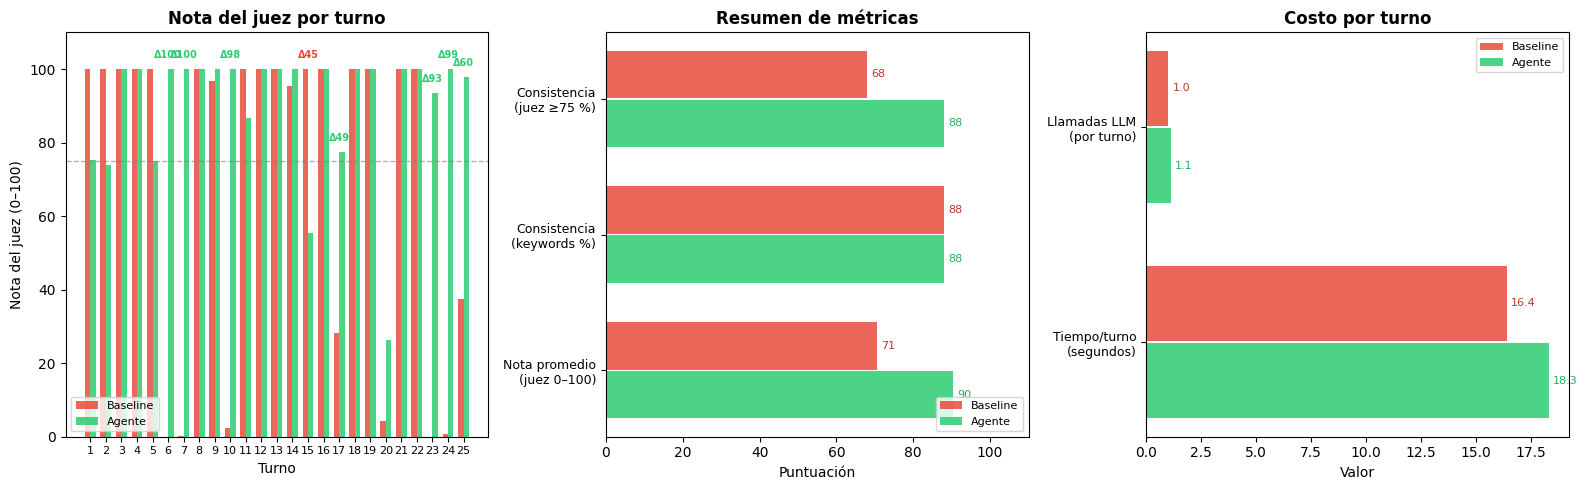

Guardada: comparacion_dm.png


In [14]:
# ────────────────────────────────────────────────────────────────────────────
# 6.2 Gráficos comparativos
# ────────────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# ── 1. Nota del juez por turno (barras lado a lado — el gráfico principal) ──
ax = axes[0]
turns = list(range(1, n + 1))
w = 0.35
x_pos = range(n)
ax.bar([x - w/2 for x in x_pos], scores_baseline_judge, w,
       label="Baseline", color="#e74c3c", alpha=0.85)
ax.bar([x + w/2 for x in x_pos], scores_agent_judge, w,
       label="Agente", color="#2ecc71", alpha=0.85)
ax.axhline(y=75, color="gray", linestyle="--", alpha=0.6, linewidth=1)
ax.set_xticks(x_pos)
ax.set_xticklabels(turns, fontsize=8)
ax.set_xlabel("Turno")
ax.set_ylabel("Nota del juez (0–100)")
ax.set_title("Nota del juez por turno", fontweight="bold")
ax.legend(fontsize=8, loc="lower left")
ax.set_ylim(0, 110)
# Anotar turnos donde la diferencia es grande
for i in range(n):
    diff = scores_agent_judge[i] - scores_baseline_judge[i]
    if abs(diff) > 30:
        winner = scores_agent_judge[i] if diff > 0 else scores_baseline_judge[i]
        color = "#2ecc71" if diff > 0 else "#e74c3c"
        label = "A" if diff > 0 else "B"
        ax.annotate(f"Δ{abs(diff):.0f}", xy=(i, winner + 3),
                    fontsize=7, ha="center", fontweight="bold", color=color)

# ── 2. Resumen: nota promedio + consistencia (horizontal) ──
ax = axes[1]
metrics = ["Nota promedio\n(juez 0–100)", "Consistencia\n(keywords %)", "Consistencia\n(juez ≥75 %)"]
baseline_vals = [b_avg_judge, b_ok_kw/n*100, b_ok_judge/n*100]
agent_vals = [a_avg_judge, a_ok_kw/n*100, a_ok_judge/n*100]
y_pos = range(len(metrics))
ax.barh([y + 0.18 for y in y_pos], baseline_vals, 0.35,
        label="Baseline", color="#e74c3c", alpha=0.85)
ax.barh([y - 0.18 for y in y_pos], agent_vals, 0.35,
        label="Agente", color="#2ecc71", alpha=0.85)
ax.set_yticks(y_pos)
ax.set_yticklabels(metrics, fontsize=9)
ax.set_xlabel("Puntuación")
ax.set_title("Resumen de métricas", fontweight="bold")
ax.set_xlim(0, 110)
ax.legend(fontsize=8, loc="lower right")
# Anotar valores
for i, (bv, av) in enumerate(zip(baseline_vals, agent_vals)):
    ax.text(bv + 1, i + 0.18, f"{bv:.0f}", va="center", fontsize=8, color="#c0392b")
    ax.text(av + 1, i - 0.18, f"{av:.0f}", va="center", fontsize=8, color="#27ae60")

# ── 3. Tiempo y costo ──
ax = axes[2]
categories = ["Tiempo/turno\n(segundos)", "Llamadas LLM\n(por turno)"]
b_vals = [t_baseline/n_turns_baseline, 1.0]  # baseline: 1 llamada por turno
a_vals = [t_agent/n_turns_agent, t_agent/t_baseline * n_turns_baseline/n_turns_agent]  # estimado
y_pos2 = range(len(categories))
ax.barh([y + 0.18 for y in y_pos2], b_vals, 0.35,
        label="Baseline", color="#e74c3c", alpha=0.85)
ax.barh([y - 0.18 for y in y_pos2], a_vals, 0.35,
        label="Agente", color="#2ecc71", alpha=0.85)
ax.set_yticks(y_pos2)
ax.set_yticklabels(categories, fontsize=9)
ax.set_xlabel("Valor")
ax.set_title("Costo por turno", fontweight="bold")
ax.legend(fontsize=8)
for i, (bv, av) in enumerate(zip(b_vals, a_vals)):
    ax.text(bv + 0.2, i + 0.18, f"{bv:.1f}", va="center", fontsize=8, color="#c0392b")
    ax.text(av + 0.2, i - 0.18, f"{av:.1f}", va="center", fontsize=8, color="#27ae60")

plt.tight_layout()
plt.savefig("comparacion_dm.png", dpi=150, bbox_inches="tight")
plt.show()
print("Guardada: comparacion_dm.png")

## 7. Demo interactiva

Celda para jugar una partida en vivo con el agente. Ejecutar y escribir acciones en el input. Escribir `salir` para terminar.

In [15]:
# ────────────────────────────────────────────────────────────────────────────
# 7. Demo interactiva (para la presentación — ejecutar manualmente)
# ────────────────────────────────────────────────────────────────────────────
# Esta celda requiere input del usuario. Ejecutar solo en modo interactivo.
# Para ejecutar: seleccionar esta celda y presionar Shift+Enter.

import sys

def demo_interactiva():
    demo_dm = AgentDM(app)

    print("=" * 60)
    print("  DUNGEON MASTER - Demo interactiva")
    print("  Escribe tus acciones. 'salir' para terminar.")
    print("=" * 60)

    intro = demo_dm.play("Comienzo mi aventura. Describe donde estoy.")
    print(f"\nDM: {intro}")
    print(f"\n{_state_summary()}")

    while True:
        try:
            action = input("\n> Tu accion: ").strip()
        except (EOFError, KeyboardInterrupt):
            break
        if not action or action.lower() == "salir":
            print("\nFin de la partida. ¡Gracias por jugar!")
            break
        response = demo_dm.play(action)
        print(f"\nDM: {response}")
        print(f"\n{_state_summary()}")

# Solo ejecutar si estamos en modo interactivo (Jupyter con frontend)
try:
    get_ipython()  # existe en Jupyter
    # Verificar si stdin está disponible
    if hasattr(sys.stdin, 'closed') and not sys.stdin.closed:
        print("Celda de demo interactiva lista. Descomenta la línea de abajo y ejecuta manualmente:")
        print("# demo_interactiva()")
    else:
        print("(Modo batch detectado — demo interactiva desactivada)")
except NameError:
    print("(No estamos en Jupyter — demo interactiva desactivada)")

Celda de demo interactiva lista. Descomenta la línea de abajo y ejecuta manualmente:
# demo_interactiva()


## 8. Conclusiones

### Resultados principales

Con **qwen2.5:7B** y una secuencia de **25 turnos** diseñados para evaluar exploración, reglas, combate, navegación y memoria a largo plazo:

| Métrica | Baseline | Agente |
|---------|----------|--------|
| Keywords (binaria) | 22/25 (88%) | 22/25 (88%) |
| Juez ≥ 3 (binaria) | 17/25 (68%) | 22/25 (88%) |
| **Nota promedio del juez (0–100)** | **70.6** | **90.5** |

### Análisis turno por turno

Los promedios globales de keywords son idénticos, pero el **LLM-as-judge con logprobs** revela una diferencia de **+20 puntos** a favor del agente. Los turnos donde la ventaja es más clara:

- **Movimiento ilegal (turnos 6–7)**: el baseline permitió teletransportarse del bosque a la herrería sin pasar por la plaza; el agente, que consulta `check_state` y el mapa de conexiones, lo bloqueó correctamente. Juez: 0 vs 100.
- **Combate y HP (turno 10)**: tras recibir daño del goblin, el agente reportó HP exactos (15/20) via `check_state`; el baseline inventó valores distintos. Juez: 2 vs 100.
- **Navegación con reglas (turnos 23–24)**: el agente consultó conexiones y rechazó un movimiento directo taberna→herrería; el baseline lo permitió sin verificar. Juez: 0–1 vs 93–100.
- **Memoria de eventos (turno 17)**: al preguntar por la pelea del goblin, el agente recordó detalles del combate con más precisión. Juez: 28 vs 77.
- **Objeto ya recogido (turno 20)**: el agente reconoció que la antorcha ya no estaba disponible; el baseline fue ambiguo. Juez: 4 vs 26.

### ¿Por qué funciona el agente?

El patrón **ReAct** (Yao et al., 2023) implementado con LangGraph permite al modelo:

1. **Consultar estado real** antes de narrar (`check_state` → respuesta informada)
2. **Validar reglas del mundo** antes de actuar (`move_to` verifica conexiones)
3. **Modificar estado de forma atómica** (`attack`, `use_potion`, `add_item` modifican `game_state` directamente)

Esto convierte al LLM de un generador de texto libre a un **agente con grounding**: sus respuestas están ancladas a un estado externo verificable, no solo al contexto de la conversación.

### Limitaciones

- **qwen2.5:7B es sorprendentemente capaz**: con 128K tokens de contexto, el baseline mantiene coherencia narrativa aceptable en 25 turnos. La diferencia sería más dramática con modelos más pequeños o ventanas más cortas.
- **El agente es ~12% más lento** (916s vs 820s) por los ciclos adicionales de tool-calling.
- **Keywords y juez no siempre concuerdan** (60% de concordancia): los keywords son binarios y superficiales; el juez evalúa calidad semántica.

### Método de evaluación

Se utilizó **LLM-as-judge con logprobs** siguiendo el patrón de la Semana 2 Clase 3: el juez genera un dígito 0–4, se extraen las probabilidades de cada token-dígito, y la nota es el valor esperado × 25. Esto produce puntuaciones continuas más informativas que una clasificación discreta.

## 9. Declaracion de uso de IAG

Este proyecto fue desarrollado con asistencia de inteligencia artificial generativa:

- **Claude (Anthropic)**: asistencia en la estructuracion del notebook, diseno de la arquitectura del agente, redaccion de celdas de codigo y texto.
- **Ollama (modelo local)**: el LLM que ejecuta tanto la linea base como el agente propuesto.

Todo el codigo fue revisado, ejecutado y validado por el estudiante. Las decisiones de diseno (estructura del mundo, herramientas del agente, metricas de evaluacion, secuencia de prueba) son del estudiante.

---

*Proyecto Final — NLP (MMIA 6021 4889) — Pablo Encalada — Octubre 2026*